# Notebook 06: Final Visualizations

**Project:** Exploring the Relationship Between Fuel and Grocery Prices in Ireland (2016–2026)

**Goal:** Turn the results of Notebooks 02–05 into 5 clean, presentation-ready charts for a general audience (Irish households). Each chart is shown on a projector for about a minute, so every chart is simple and readable from the back of a room.

| Chart | Question | Based on |
|---|---|---|
| 1. The big picture | How have fuel and food prices changed since 2016? | Notebooks 02 and 03 |
| 2. Fuel swings, food doesn't | How much do prices move from month to month during major events? | Notebook 03 |
| 3. The delay, shown directly | Do food prices react to fuel prices straight away, or later? | Notebooks 02 and 05 |
| 4. Correlation vs lag | How long is the delay, and is the link the same at all times? | Notebook 05 |
| 5. Which groceries rose most | Did fresh and long-lasting groceries rise by the same amount? | Notebook 04 |

Every number in this notebook is calculated from the data below, and each chart title is checked against the data before the chart is drawn.

Data (local `data/` folder): `cleaned_fuel_grocery_data.csv` (Notebook 01), `02_trend_analysis_output.csv` (Notebook 02) and `04_grocery_groups_output.csv` (Notebook 04).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Folders (works from notebooks/ in VS Code or from the repo root)
DATA_DIR = '../data' if os.path.basename(os.getcwd()) == 'notebooks' else 'data'
IMG_DIR = '../images' if os.path.basename(os.getcwd()) == 'notebooks' else 'images'
os.makedirs(IMG_DIR, exist_ok=True)

# 2. Load datasets from the local data folder
df = pd.read_csv(f'{DATA_DIR}/cleaned_fuel_grocery_data.csv', parse_dates=['Month_DT'])
trend_df = pd.read_csv(f'{DATA_DIR}/02_trend_analysis_output.csv', parse_dates=['Month_DT'])
groups_df = pd.read_csv(f'{DATA_DIR}/04_grocery_groups_output.csv', parse_dates=['Month_DT'])

# shorter name for the food column
df = df.rename(columns={'Food and non-alcoholic beverages': 'Food'})

# 3. Team colours
colours = {
    'Petrol': '#1F77B4',        # blue
    'Diesel': '#C26A1C',        # burnt orange
    'Food': '#2CA02C',          # green
    'Perishable': '#2CA02C',    # green
    'Shelf-stable': '#98DF8A',  # light green (dashed line)
}
shelf_text_colour = '#5A9E4B'   # mid green - light green text is hard to read on a projector
event_colour = '#D9D9D9'        # light grey - event shading
note_colour = '#555555'         # dark grey - notes and event names
without_colour = '#8C8C8C'      # mid grey - "without 2021-2023" line in Chart 4

# 4. Event periods - exact dates from Notebook 03
events = {
    'COVID-19 lockdowns':          ('2020-03-01', '2020-06-30'),
    'Post-COVID supply issues':    ('2021-01-01', '2021-12-31'),
    'Ukraine invasion':            ('2022-02-01', '2022-06-30'),
    'ECB rate hikes':              ('2022-07-01', '2023-09-30'),
    'Strait of Hormuz disruption': ('2026-03-01', '2026-04-30'),
    'Post-Hormuz aftermath':       ('2026-05-01', '2026-09-30'),
}

# short names that fit above the shaded areas
event_short_names = {
    'COVID-19 lockdowns': 'COVID',
    'Post-COVID supply issues': 'Supply issues',
    'Ukraine invasion': 'Ukraine',
    'ECB rate hikes': 'ECB rate hikes',
    'Strait of Hormuz disruption': 'Hormuz',
    'Post-Hormuz aftermath': 'After Hormuz',
}

# 5. Presentation style for every chart (readable from the back of a room)
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'axes.titlesize': 16,
    'axes.titleweight': 'bold',
    'axes.labelsize': 13,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'lines.linewidth': 3,
})
FIGSIZE = (12, 6.5)

# year ticks for the time charts (no ticks in the empty space used for the line labels)
year_ticks = pd.date_range('2016-01-01', '2026-01-01', freq='YS')


def shade_events(ax, label=True):
    """Shade each event period in light grey and write its short name at the top of the chart."""
    for i, (event, (start, end)) in enumerate(events.items()):
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        ax.axvspan(start, end, color=event_colour, alpha=0.6, linewidth=0, zorder=0)
        if label:
            # names alternate between two rows so neighbouring periods don't overlap
            y = 0.97 if i % 2 == 0 else 0.91
            ax.text(start + (end - start) / 2, y, event_short_names[event],
                    transform=ax.get_xaxis_transform(), ha='center', va='top',
                    fontsize=11, color=note_colour)


def add_source(fig, text):
    """Add the source line at the bottom right of the figure."""
    fig.text(0.99, 0.01, text, ha='right', va='bottom', fontsize=11, color=note_colour)


# 6. Print checks
print("=== Data Ranges ===")
print(f"Fuel and food index:  {df['Month_DT'].min():%b %Y} to {df['Month_DT'].max():%b %Y} ({len(df)} months)")
print(f"Trend analysis:       {trend_df['Month_DT'].min():%b %Y} to {trend_df['Month_DT'].max():%b %Y} ({len(trend_df)} months)")
print(f"Grocery groups:       {groups_df['Month_DT'].min():%b %Y} to {groups_df['Month_DT'].max():%b %Y} ({len(groups_df)} months)")
print(f"Missing values: {df.isnull().sum().sum()} (fuel/food), "
      f"{groups_df[['Perishable', 'Shelf-stable']].isnull().sum().sum()} (grocery groups)")

=== Data Ranges ===
Fuel and food index:  Jan 2016 to Sep 2026 (129 months)
Trend analysis:       Jan 2016 to Sep 2026 (129 months)
Grocery groups:       Jan 2016 to Sep 2026 (129 months)
Missing values: 0 (fuel/food), 0 (grocery groups)


## Chart 1: The Big Picture

**Question:** How have petrol, diesel and food prices changed since 2016?

**What to notice:** Fuel prices jumped twice, in 2022 and again in 2026, and fell in between. Food prices climbed more slowly from 2022 onwards and have not come back down.

**Why this chart type:** A line chart is the clearest way to show how prices change over time. All three series use the same index (December 2023 = 100), so they can share one y-axis and be compared directly. The lines are labelled at their ends instead of using a legend, so the audience doesn't have to look back and forth.

**Alternative we considered:** Three small charts side by side, one per series. We didn't use it because the main point is the comparison between fuel and food, which is much easier to see when the lines are on the same axis.

In [2]:
import pandas as pd

# 1. Highest index value in each year
yearly_max = df.groupby(df['Month_DT'].dt.year)[['Petrol', 'Diesel', 'Food']].max()

# 2. Check "fuel spiked in 2022 and 2026": both years are higher than every other year
for fuel in ['Petrol', 'Diesel']:
    other_years_max = yearly_max.loc[~yearly_max.index.isin([2022, 2026]), fuel].max()
    assert yearly_max.loc[2022, fuel] > other_years_max, f"{fuel}: 2022 is not a spike"
    assert yearly_max.loc[2026, fuel] > other_years_max, f"{fuel}: 2026 is not a spike"

# 3. Check "food rose more slowly": largest 12-month rise of food vs fuel
max_rise = trend_df[['Petrol_YoY_Pct', 'Diesel_YoY_Pct', 'CPI_YoY_Pct']].max()
assert max_rise['CPI_YoY_Pct'] < max_rise[['Petrol_YoY_Pct', 'Diesel_YoY_Pct']].min() / 2

# 4. Check "food stayed high": the latest food value is within 1% of its highest value
food_latest = df['Food'].iloc[-1]
food_low_month = df.loc[df['Food'].idxmin(), 'Month_DT']
assert food_latest >= 0.99 * df['Food'].max()

print("=== Chart 1 Checks ===")
print("Highest index value per year:")
print(yearly_max.round(1))
print(f"\nPetrol peak: {df['Petrol'].max():.1f} in {df.loc[df['Petrol'].idxmax(), 'Month_DT']:%B %Y}")
print(f"Diesel peak: {df['Diesel'].max():.1f} in {df.loc[df['Diesel'].idxmax(), 'Month_DT']:%B %Y}")
print(f"Largest 12-month rise: petrol +{max_rise['Petrol_YoY_Pct']:.1f}%, diesel +{max_rise['Diesel_YoY_Pct']:.1f}%, "
      f"food +{max_rise['CPI_YoY_Pct']:.1f}%")
print(f"Food: lowest {df['Food'].min():.1f} ({food_low_month:%B %Y}), highest {df['Food'].max():.1f}, "
      f"latest {food_latest:.1f} ({df['Month_DT'].iloc[-1]:%B %Y}) "
      f"-> +{(food_latest / df['Food'].min() - 1) * 100:.1f}% since its lowest point")

=== Chart 1 Checks ===
Highest index value per year:
          Petrol  Diesel   Food
Month_DT                       
2016        77.0    71.0   90.7
2017        80.2    73.5   88.4
2018        87.0    81.6   86.9
2019        85.9    79.8   85.9
2020        85.9    80.4   84.7
2021       100.4    94.1   84.7
2022       125.5   122.0   94.7
2023       108.1   108.4  100.0
2024       106.3   103.6  102.0
2025       105.8   104.2  106.3
2026       114.5   126.2  106.6

Petrol peak: 125.5 in June 2022
Diesel peak: 126.2 in April 2026
Largest 12-month rise: petrol +43.8%, diesel +50.8%, food +13.1%
Food: lowest 82.8 (January 2021), highest 106.6, latest 106.4 (September 2026) -> +28.5% since its lowest point


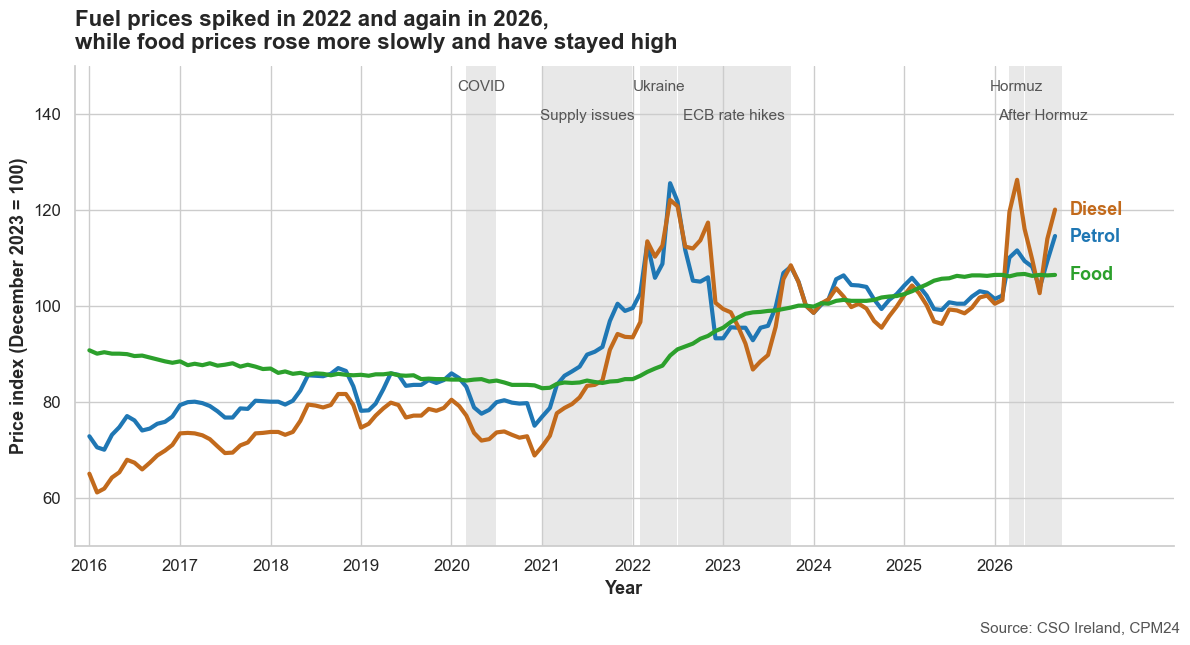

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Title (checked in the cell above)
title = ("Fuel prices spiked in 2022 and again in 2026,\n"
         "while food prices rose more slowly and have stayed high")

fig, ax = plt.subplots(figsize=FIGSIZE)

# 2. Event periods in light grey, named at the top
shade_events(ax)

# 3. One line per series, all on the same y-axis
last_month = df['Month_DT'].iloc[-1]
for series in ['Petrol', 'Diesel', 'Food']:
    ax.plot(df['Month_DT'], df[series], color=colours[series], linewidth=3)
    # label the line at its end instead of using a legend
    ax.text(last_month + pd.Timedelta(days=60), df[series].iloc[-1], series,
            color=colours[series], fontsize=13, fontweight='bold', va='center')

# 4. Axes and title
ax.set_title(title, loc='left', pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Price index (December 2023 = 100)')
ax.set_xticks(year_ticks)
ax.set_xticklabels([d.year for d in year_ticks])
ax.set_xlim(df['Month_DT'].iloc[0] - pd.Timedelta(days=60), last_month + pd.Timedelta(days=480))
ax.set_ylim(50, 150)
sns.despine()

add_source(fig, 'Source: CSO Ireland, CPM24')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{IMG_DIR}/final_1_fuel_and_food_prices_big_picture.png', dpi=300, bbox_inches='tight')
plt.show()

## Chart 2: Fuel Swings, Food Doesn't

**Question:** How much do fuel and food prices move from one month to the next, in normal times and during major events?

**What to notice:** In every period the fuel bars are much longer than the food bars. During the Ukraine invasion, petrol and diesel moved 4–5 times more per month than in normal months, while food moved about 1% a month.

**Why this chart type:** Horizontal bars leave room to write the full period names and the number of months (n) on the left, where they are easy to read. Grouping the three bars for each period makes the fuel vs food comparison immediate. We use the *size* of each monthly change (rises and falls both count), so a big fall like the COVID-19 drop counts as much as a big rise.

**Alternative we considered:** A heatmap (periods × petrol/diesel/food, coloured by size of change). We didn't use it because the audience would have to compare shades of colour instead of bar lengths, which is much harder from the back of a room.

*Method note:* Notebook 03 measured the **spread** of the monthly changes (standard deviation) and found fuel was about 3–4 times more volatile than normal during the Ukraine invasion. Here we use the **average size** of the monthly change, which is easier to explain to a general audience and gives 4–5 times. Both measures tell the same story. Some periods are short (n = 2 to 5 months), so their bars are less reliable.

In [4]:
import numpy as np
import pandas as pd

# 1. Monthly % change for each series (same method as Notebook 03)
change_df = df[['Month_DT', 'Petrol', 'Diesel', 'Food']].copy()
for series in ['Petrol', 'Diesel', 'Food']:
    change_df[series] = change_df[series].pct_change() * 100

# 2. Label each month: "Normal" unless it falls inside an event period
change_df['Period'] = 'Normal'
for event, (start, end) in events.items():
    in_event = (change_df['Month_DT'] >= start) & (change_df['Month_DT'] <= end)
    change_df.loc[in_event, 'Period'] = event
period_order = ['Normal'] + list(events.keys())

# 3. Average size of the monthly change (absolute value, so rises and falls count the same)
avg_size = change_df.groupby('Period')[['Petrol', 'Diesel', 'Food']].agg(lambda x: x.abs().mean()).loc[period_order]
n_months = change_df.groupby('Period')['Food'].count().loc[period_order]

# 4. How many times bigger than in normal months
times_normal = avg_size / avg_size.loc['Normal']

# 5. Numbers for the title: petrol and diesel during the Ukraine invasion
ukraine_ratio = times_normal.loc['Ukraine invasion', ['Petrol', 'Diesel']]
ratio_low, ratio_high = int(round(ukraine_ratio.min())), int(round(ukraine_ratio.max()))
ratio_text = f"{ratio_low}–{ratio_high}" if ratio_low != ratio_high else f"about {ratio_low}"

# 6. Check against Notebook 03 (same month counts) and check the title claims
assert n_months.tolist() == [85, 4, 12, 5, 15, 2, 5], "Month counts differ from Notebook 03"
assert (avg_size['Food'] < avg_size[['Petrol', 'Diesel']].min(axis=1)).all(), "Food moved more than fuel in some period"

print("=== Chart 2 Checks ===")
print("Average size of monthly change (%):")
print(avg_size.assign(n=n_months).round(2))
print("\nTimes bigger than in normal months:")
print(times_normal.round(1))
print(f"\nUkraine invasion: petrol {ukraine_ratio['Petrol']:.1f}x and diesel {ukraine_ratio['Diesel']:.1f}x normal "
      f"-> title says '{ratio_text} times'")
print(f"Ukraine invasion: fuel moved {avg_size.loc['Ukraine invasion', 'Petrol'] / avg_size.loc['Ukraine invasion', 'Food']:.1f}x (petrol) and "
      f"{avg_size.loc['Ukraine invasion', 'Diesel'] / avg_size.loc['Ukraine invasion', 'Food']:.1f}x (diesel) more than food")

=== Chart 2 Checks ===
Average size of monthly change (%):
                             Petrol  Diesel  Food   n
Period                                               
Normal                         1.51    1.73  0.31  85
COVID-19 lockdowns             2.49    2.45  0.30   4
Post-COVID supply issues       2.60    2.72  0.37  12
Ukraine invasion               7.56    6.83  1.13   5
ECB rate hikes                 3.32    4.15  0.69  15
Strait of Hormuz disruption    4.55   11.84  0.33   2
Post-Hormuz aftermath          3.46    7.27  0.17   5

Times bigger than in normal months:
                             Petrol  Diesel  Food
Period                                           
Normal                          1.0     1.0   1.0
COVID-19 lockdowns              1.7     1.4   0.9
Post-COVID supply issues        1.7     1.6   1.2
Ukraine invasion                5.0     4.0   3.6
ECB rate hikes                  2.2     2.4   2.2
Strait of Hormuz disruption     3.0     6.9   1.0
Post-Hormuz afterm

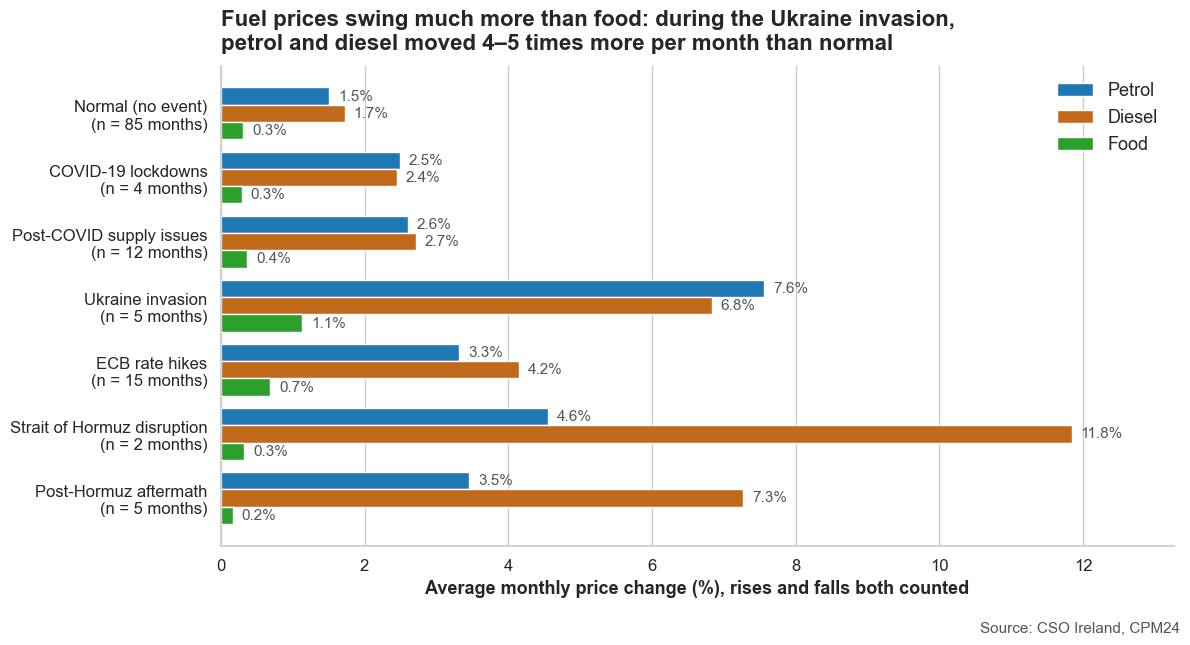

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Title (numbers calculated in the cell above)
title = (f"Fuel prices swing much more than food: during the Ukraine invasion,\n"
         f"petrol and diesel moved {ratio_text} times more per month than normal")

# 2. Period labels with the number of months (n)
period_labels = [f"{'Normal (no event)' if p == 'Normal' else p}\n(n = {n_months[p]} months)" for p in period_order]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 3. Three bars per period: petrol, diesel, food
y = np.arange(len(period_order))
bar_height = 0.27
for i, series in enumerate(['Petrol', 'Diesel', 'Food']):
    positions = y + (i - 1) * bar_height
    ax.barh(positions, avg_size[series], height=bar_height, color=colours[series], label=series)
    # value at the end of each bar
    for pos, value in zip(positions, avg_size[series]):
        ax.text(value + 0.12, pos, f"{value:.1f}%", va='center', fontsize=11, color=note_colour)

# 4. Axes, legend and title
ax.set_yticks(y)
ax.set_yticklabels(period_labels)
ax.invert_yaxis()   # Normal at the top, then the events in time order
ax.set_xlabel('Average monthly price change (%), rises and falls both counted')
ax.set_xlim(0, avg_size.max().max() * 1.12)
ax.grid(axis='y', visible=False)
ax.legend(loc='upper right', frameon=False, fontsize=13)
ax.set_title(title, loc='left', pad=12)
sns.despine()

add_source(fig, 'Source: CSO Ireland, CPM24')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{IMG_DIR}/final_2_monthly_price_swings_by_period.png', dpi=300, bbox_inches='tight')
plt.show()

## Chart 3: The Delay, Shown Directly

**Question:** Do food prices react to fuel prices straight away, or later?

**What to notice:** Diesel price inflation (the change compared with the same month a year earlier) peaked in June 2022. Food price inflation peaked about 10 months later, in spring 2023.

**Why this chart type:** Two panels with the same time axis put the two peaks directly above each other, so the delay can be seen without knowing any statistics. Each panel has its own scale, because diesel moved about four times more than food. Using two separate panels instead of two y-axes on one chart avoids stretching the scales to make the lines look more connected than they really are.

**Alternative we considered:** Both lines on one chart with one y-axis. We didn't use it because next to diesel's +50% the food line looks almost flat, and its peak is hard to see.

In [6]:
import pandas as pd

# 1. Year-on-year % change for diesel and food (from Notebook 02)
yoy_df = trend_df[['Month_DT', 'Diesel_YoY_Pct', 'CPI_YoY_Pct']].dropna()

# 2. Peak month of each series
diesel_peak = yoy_df.loc[yoy_df['Diesel_YoY_Pct'].idxmax()]
food_peak = yoy_df.loc[yoy_df['CPI_YoY_Pct'].idxmax()]


def months_between(start, end):
    """Number of whole months from start to end."""
    return (end.year - start.year) * 12 + (end.month - start.month)


gap_months = months_between(diesel_peak['Month_DT'], food_peak['Month_DT'])

# 3. Food stayed almost exactly at its peak for several months (a flat top), so also find where it starts
food_top = yoy_df.loc[yoy_df['CPI_YoY_Pct'] >= food_peak['CPI_YoY_Pct'] - 0.05, 'Month_DT']
gap_to_top_start = months_between(diesel_peak['Month_DT'], food_top.min())

# 4. Check: food peaked after diesel
assert gap_months > 0

print("=== Chart 3 Checks ===")
print(f"Diesel peak: +{diesel_peak['Diesel_YoY_Pct']:.1f}% in {diesel_peak['Month_DT']:%B %Y}")
print(f"Food peak:   +{food_peak['CPI_YoY_Pct']:.1f}% in {food_peak['Month_DT']:%B %Y}")
print(f"Gap between the peaks: {gap_months} months")
print(f"Food stayed within 0.05 points of its peak from {food_top.min():%B %Y} to {food_top.max():%B %Y} "
      f"({gap_to_top_start}–{gap_months} months after the diesel peak)")
print(yoy_df.set_index('Month_DT').loc['2022-12':'2023-06', 'CPI_YoY_Pct'].round(2))

=== Chart 3 Checks ===
Diesel peak: +50.8% in June 2022
Food peak:   +13.1% in April 2023
Gap between the peaks: 10 months
Food stayed within 0.05 points of its peak from February 2023 to April 2023 (8–10 months after the diesel peak)
Month_DT
2022-12-01    11.81
2023-01-01    12.63
2023-02-01    13.11
2023-03-01    13.11
2023-04-01    13.12
2023-05-01    12.69
2023-06-01    10.16
Name: CPI_YoY_Pct, dtype: float64


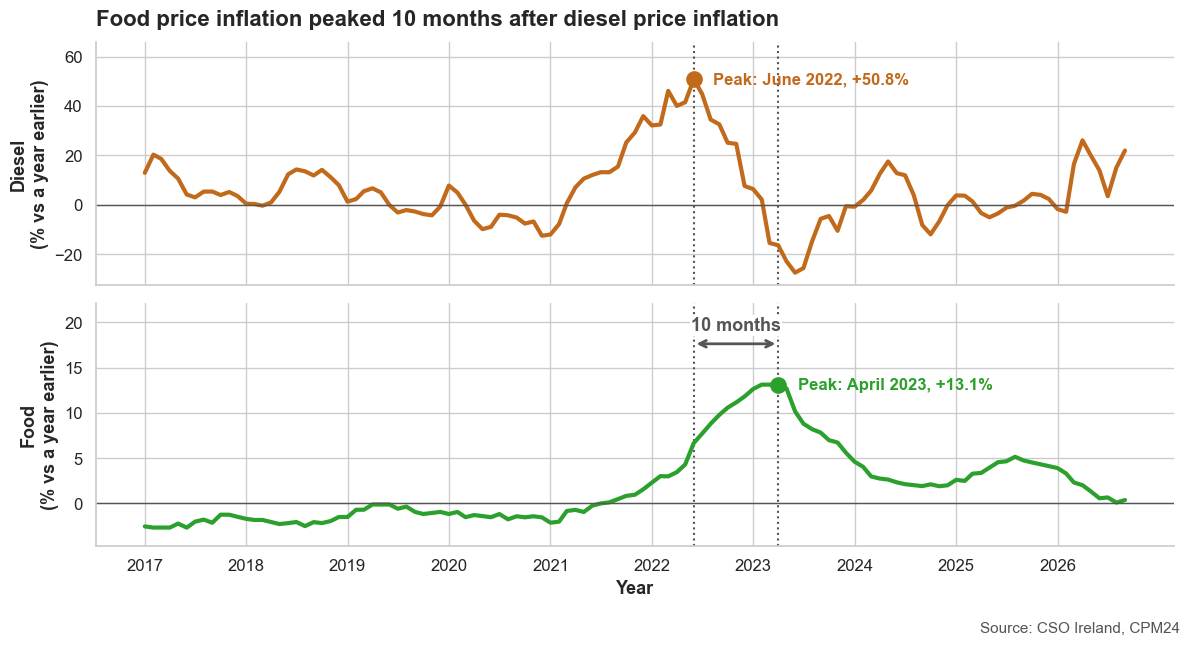

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Title (gap calculated in the cell above)
title = f"Food price inflation peaked {gap_months} months after diesel price inflation"

fig, (ax_diesel, ax_food) = plt.subplots(2, 1, figsize=FIGSIZE, sharex=True)

# 2. One panel per series, each with its own scale (no dual y-axes)
panels = [
    (ax_diesel, 'Diesel_YoY_Pct', 'Diesel', diesel_peak),
    (ax_food, 'CPI_YoY_Pct', 'Food', food_peak),
]
for ax, column, series, peak in panels:
    ax.plot(yoy_df['Month_DT'], yoy_df[column], color=colours[series], linewidth=3)
    ax.axhline(0, color=note_colour, linewidth=1)
    ax.set_ylabel(f"{series}\n(% vs a year earlier)")

    # mark the peak with a dot and a label (month and value)
    ax.plot(peak['Month_DT'], peak[column], 'o', color=colours[series], markersize=11, zorder=5)
    ax.annotate(f"Peak: {peak['Month_DT']:%B %Y}, +{peak[column]:.1f}%",
                xy=(peak['Month_DT'], peak[column]), xytext=(14, 0), textcoords='offset points',
                va='center', fontsize=12, fontweight='bold', color=colours[series])

    # dotted lines through both peak months, on both panels
    for month in [diesel_peak['Month_DT'], food_peak['Month_DT']]:
        ax.axvline(month, color=note_colour, linestyle=':', linewidth=1.5, zorder=1)

# 3. Room above each peak for the labels and the gap arrow
ax_diesel.set_ylim(yoy_df['Diesel_YoY_Pct'].min() - 5, diesel_peak['Diesel_YoY_Pct'] + 15)
ax_food.set_ylim(yoy_df['CPI_YoY_Pct'].min() - 2, food_peak['CPI_YoY_Pct'] + 9)

# 4. Arrow showing the gap between the two peaks
arrow_y = food_peak['CPI_YoY_Pct'] + 4.5
ax_food.annotate('', xy=(food_peak['Month_DT'], arrow_y), xytext=(diesel_peak['Month_DT'], arrow_y),
                 arrowprops=dict(arrowstyle='<->', color=note_colour, linewidth=2))
ax_food.text(diesel_peak['Month_DT'] + (food_peak['Month_DT'] - diesel_peak['Month_DT']) / 2, arrow_y + 1,
             f"{gap_months} months", ha='center', va='bottom', fontsize=13, fontweight='bold', color=note_colour,
             bbox=dict(facecolor='white', edgecolor='none', pad=1))   # white box so the dotted lines don't cross the text

# 5. Axes and title
ax_food.set_xlabel('Year')
ax_food.set_xticks(year_ticks[1:])
ax_food.set_xticklabels([d.year for d in year_ticks[1:]])
ax_diesel.set_title(title, loc='left', pad=12)
sns.despine()

add_source(fig, 'Source: CSO Ireland, CPM24')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{IMG_DIR}/final_3_diesel_and_food_inflation_peaks.png', dpi=300, bbox_inches='tight')
plt.show()

## Chart 4: Correlation vs Lag

**Question:** Over the whole period, how closely does food price inflation follow fuel price inflation from earlier months, and is the link the same at all times?

**What to notice:** The link is strongest when fuel leads food by 9–12 months (a correlation of about 0.6). But the dashed grey line shows that if we leave out 2021–2023, the link disappears and even turns negative. So the delay mainly comes from the 2021–23 price surge.

**Why this chart type:** The lags go in order from 0 to 18 months, so a line chart shows the shape clearly: the link rises, peaks at 9–12 months and then falls. Putting the "without 2021–2023" line on the same chart keeps the warning next to the finding, so the audience cannot see one without the other.

**Alternative we considered:** A scatter plot of food inflation against diesel inflation 10 months earlier. We didn't use it because it only shows one lag, hides that the choice of lag matters, and is harder for a general audience to read.

*Reading the y-axis:* a correlation of 1 means the two always move together, 0 means there is no link, and a negative value means they tend to move in opposite directions.

In [8]:
import pandas as pd

# 1. Year-on-year changes from Notebook 02
corr_df = trend_df.set_index('Month_DT')
lags = range(0, 19)

# 2. Months used for the check without 2021-2023 (based on the food month, same as Notebook 05)
without_surge = (corr_df.index < '2021-01-01') | (corr_df.index >= '2024-01-01')

# 3. Correlation between food now and fuel `lag` months earlier (same method as Notebook 05)
lag_results = []
for lag in lags:
    lag_results.append({
        'Lag_Months': lag,
        'Diesel': corr_df['CPI_YoY_Pct'].corr(corr_df['Diesel_YoY_Pct'].shift(lag)),
        'Petrol': corr_df['CPI_YoY_Pct'].corr(corr_df['Petrol_YoY_Pct'].shift(lag)),
        'Diesel_without_2021_2023': corr_df.loc[without_surge, 'CPI_YoY_Pct'].corr(
            corr_df['Diesel_YoY_Pct'].shift(lag)[without_surge]),
    })
lag_df = pd.DataFrame(lag_results).set_index('Lag_Months')

# 4. Strongest lag for each fuel
best_diesel_lag = lag_df['Diesel'].idxmax()
best_petrol_lag = lag_df['Petrol'].idxmax()

# 5. Check the title claims: strongest at 9-12 months, and negative at 9-12 months without 2021-2023
assert 9 <= best_diesel_lag <= 12 and 9 <= best_petrol_lag <= 12
assert (lag_df.loc[9:12, 'Diesel_without_2021_2023'] < 0).all()

print("=== Chart 4 Checks ===")
print(lag_df.round(3))
print(f"\nStrongest diesel lag: {best_diesel_lag} months (r = {lag_df.loc[best_diesel_lag, 'Diesel']:.2f})")
print(f"Strongest petrol lag: {best_petrol_lag} months (r = {lag_df.loc[best_petrol_lag, 'Petrol']:.2f})")
print(f"Diesel without 2021-2023 at 9-12 months: {lag_df.loc[9:12, 'Diesel_without_2021_2023'].min():.2f} "
      f"to {lag_df.loc[9:12, 'Diesel_without_2021_2023'].max():.2f}")

=== Chart 4 Checks ===
            Diesel  Petrol  Diesel_without_2021_2023
Lag_Months                                          
0           -0.019  -0.111                    -0.109
1            0.060  -0.046                    -0.165
2            0.139   0.021                    -0.230
3            0.220   0.096                    -0.260
4            0.297   0.176                    -0.279
5            0.373   0.259                    -0.313
6            0.454   0.346                    -0.358
7            0.518   0.425                    -0.398
8            0.565   0.489                    -0.413
9            0.597   0.537                    -0.416
10           0.614   0.569                    -0.409
11           0.613   0.582                    -0.366
12           0.602   0.586                    -0.309
13           0.581   0.585                    -0.275
14           0.549   0.575                    -0.215
15           0.503   0.546                    -0.169
16           0.447   0.

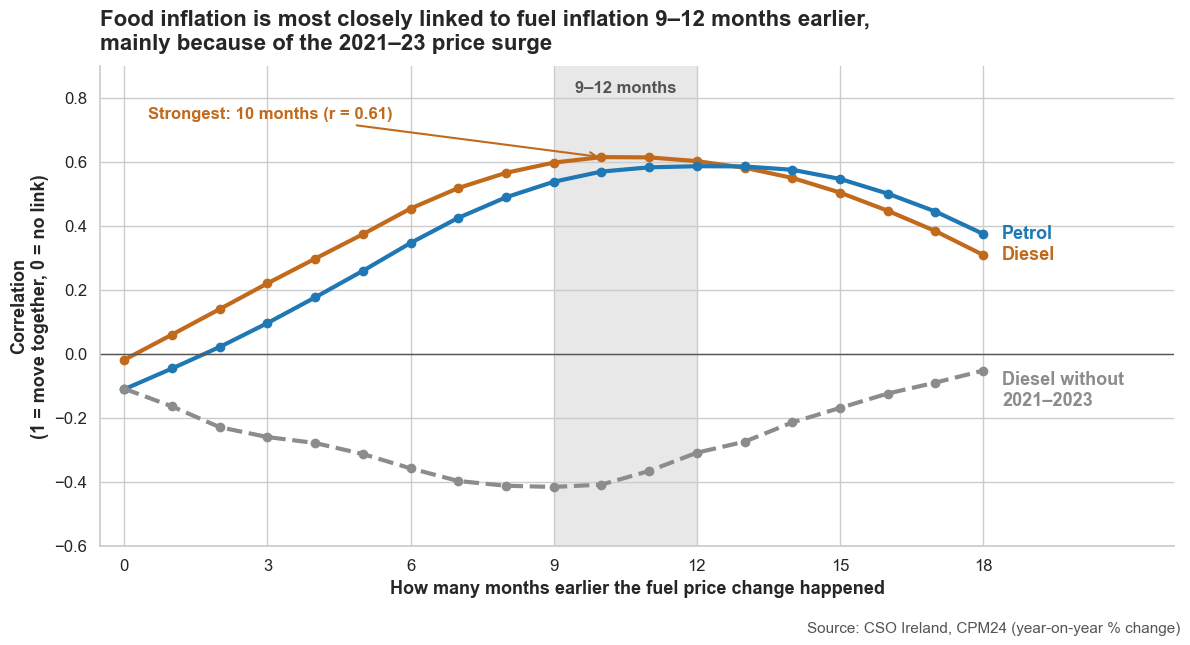

In [9]:
import matplotlib.pyplot as plt

# 1. Title (checked in the cell above)
title = ("Food inflation is most closely linked to fuel inflation 9–12 months earlier,\n"
         "mainly because of the 2021–23 price surge")

fig, ax = plt.subplots(figsize=FIGSIZE)

# 2. Shade the 9-12 month band
ax.axvspan(9, 12, color=event_colour, alpha=0.6, linewidth=0, zorder=0)
ax.text(10.5, 0.97, '9–12 months', transform=ax.get_xaxis_transform(), ha='center', va='top',
        fontsize=12, fontweight='bold', color=note_colour)

# 3. Correlation lines: diesel, petrol and diesel without 2021-2023 (dashed grey)
# (last value = vertical position of the end label: 'center' next to the line, 'top' just below it)
lines = [
    ('Diesel', colours['Diesel'], '-', 'Diesel', 'center'),
    ('Petrol', colours['Petrol'], '-', 'Petrol', 'center'),
    ('Diesel_without_2021_2023', without_colour, '--', 'Diesel without\n2021–2023', 'top'),
]
for column, colour, style, label, label_va in lines:
    ax.plot(lag_df.index, lag_df[column], color=colour, linestyle=style, linewidth=3, marker='o', markersize=6)
    # label the line at its end instead of using a legend
    ax.text(lag_df.index[-1] + 0.4, lag_df[column].iloc[-1], label,
            color=colour, fontsize=13, fontweight='bold', va=label_va)

# 4. Mark the strongest diesel lag
best_r = lag_df.loc[best_diesel_lag, 'Diesel']
ax.annotate(f"Strongest: {best_diesel_lag} months (r = {best_r:.2f})",
            xy=(best_diesel_lag, best_r), xytext=(best_diesel_lag - 9.5, best_r + 0.12),
            fontsize=12, fontweight='bold', color=colours['Diesel'],
            arrowprops=dict(arrowstyle='->', color=colours['Diesel'], linewidth=1.5))

# 5. Axes and title
ax.axhline(0, color=note_colour, linewidth=1)
ax.set_xlabel('How many months earlier the fuel price change happened')
ax.set_ylabel('Correlation\n(1 = move together, 0 = no link)')
ax.set_xticks(range(0, 19, 3))
ax.set_xlim(-0.5, 22)
ax.set_ylim(-0.6, 0.9)
ax.set_title(title, loc='left', pad=12)
sns.despine()

add_source(fig, 'Source: CSO Ireland, CPM24 (year-on-year % change)')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{IMG_DIR}/final_4_correlation_vs_lag.png', dpi=300, bbox_inches='tight')
plt.show()

## Chart 5: Which Groceries Rose Most

**Question:** Did fresh groceries and long-lasting groceries rise in price by the same amount since 2016?

**What to notice:** Perishable groceries (fresh items like milk, butter, eggs and meat) rose about 35% since January 2016, more than twice as much as shelf-stable groceries (flour, sugar, tea, pasta, jam) at about 15%. Both groups started rising in 2022.

**Why this chart type:** A line chart shows both the size of the gap and *when* it opened (from 2022, after the fuel price spike). Both groups start at the same point (January 2016 = 100), so the final value of each line is its total rise, which we label at the end of the line.

**Alternative we considered:** A simple bar chart of the total % rise for each group. It is even simpler, but it hides *when* prices rose, which is what connects this chart to the fuel price story.

*Note:* each group is the simple average of only 7 items (see Notebook 04), so one item can move a group a lot.

In [10]:
import pandas as pd

# 1. Group indices (January 2016 = 100) from Notebook 04
groups = groups_df.set_index('Month_DT')[['Perishable', 'Shelf-stable']]

# 2. Total change since January 2016
group_change = groups.iloc[-1] - 100

# 3. Check: both groups start at 100, and perishable rose more than twice as much as shelf-stable
assert (groups.iloc[0].round(6) == 100).all()
change_ratio = group_change['Perishable'] / group_change['Shelf-stable']
assert change_ratio > 2

print("=== Chart 5 Checks ===")
print(f"Change from {groups.index[0]:%B %Y} to {groups.index[-1]:%B %Y}:")
print(f"  Perishable:   {group_change['Perishable']:+.1f}%")
print(f"  Shelf-stable: {group_change['Shelf-stable']:+.1f}%")
print(f"  Ratio: {change_ratio:.2f} times")
print(f"Highest values: perishable {groups['Perishable'].max():.1f} ({groups['Perishable'].idxmax():%B %Y}), "
      f"shelf-stable {groups['Shelf-stable'].max():.1f} ({groups['Shelf-stable'].idxmax():%B %Y})")

=== Chart 5 Checks ===
Change from January 2016 to September 2026:
  Perishable:   +34.6%
  Shelf-stable: +14.6%
  Ratio: 2.37 times
Highest values: perishable 137.6 (November 2025), shelf-stable 115.3 (August 2026)


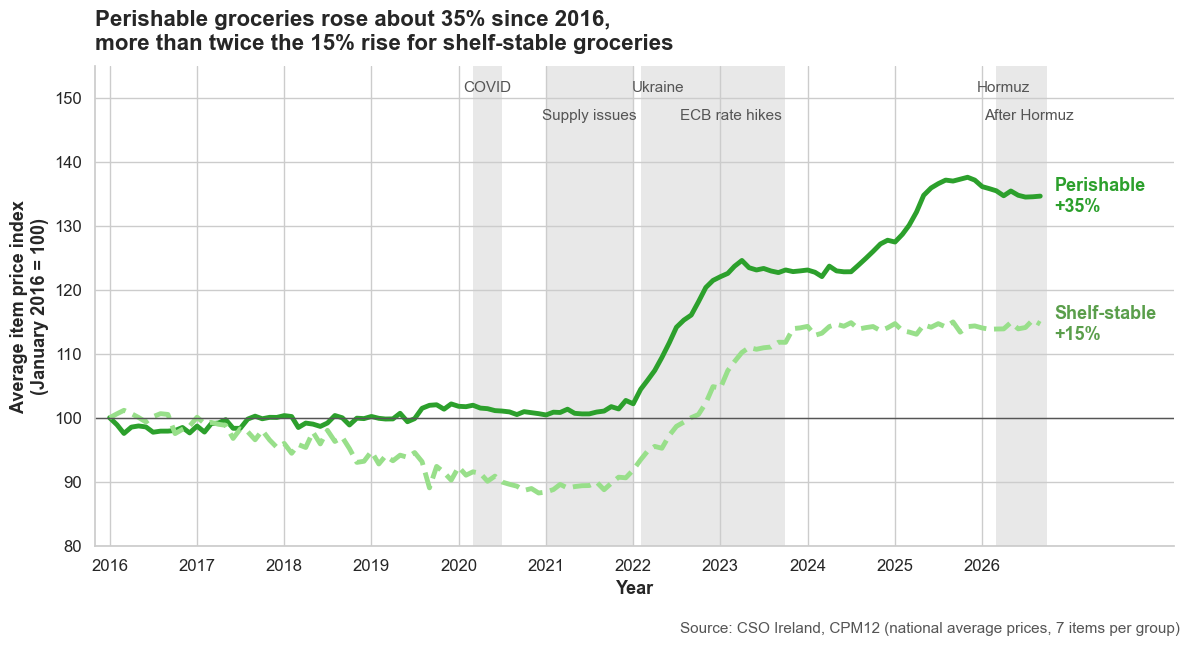

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Title (numbers calculated in the cell above)
title = (f"Perishable groceries rose about {group_change['Perishable']:.0f}% since 2016,\n"
         f"more than twice the {group_change['Shelf-stable']:.0f}% rise for shelf-stable groceries")

fig, ax = plt.subplots(figsize=FIGSIZE)

# 2. Event periods in light grey, named at the top
shade_events(ax)

# 3. One line per group, labelled at its end with the total change
group_lines = [
    ('Perishable', '-', colours['Perishable']),
    ('Shelf-stable', '--', shelf_text_colour),
]
last_month = groups.index[-1]
for group, style, text_colour in group_lines:
    ax.plot(groups.index, groups[group], color=colours[group], linestyle=style, linewidth=3.5)
    ax.text(last_month + pd.Timedelta(days=60), groups[group].iloc[-1],
            f"{group}\n{group_change[group]:+.0f}%",
            color=text_colour, fontsize=13, fontweight='bold', va='center')

# 4. Reference line at the starting level
ax.axhline(100, color=note_colour, linewidth=1)

# 5. Axes and title
ax.set_title(title, loc='left', pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Average item price index\n(January 2016 = 100)')
ax.set_xticks(year_ticks)
ax.set_xticklabels([d.year for d in year_ticks])
ax.set_xlim(groups.index[0] - pd.Timedelta(days=60), last_month + pd.Timedelta(days=560))
ax.set_ylim(80, 155)
sns.despine()

add_source(fig, 'Source: CSO Ireland, CPM12 (national average prices, 7 items per group)')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{IMG_DIR}/final_5_perishable_vs_shelf_stable_groceries.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
import os

# 1. List the final chart images saved by this notebook
print("=== Saved Charts ===")
for filename in sorted(os.listdir(IMG_DIR)):
    if filename.startswith('final_'):
        size_kb = os.path.getsize(f'{IMG_DIR}/{filename}') / 1024
        print(f"{IMG_DIR}/{filename}  ({size_kb:.0f} KB)")

=== Saved Charts ===
../images/final_1_fuel_and_food_prices_big_picture.png  (342 KB)
../images/final_2_monthly_price_swings_by_period.png  (311 KB)
../images/final_3_diesel_and_food_inflation_peaks.png  (303 KB)
../images/final_4_correlation_vs_lag.png  (320 KB)
../images/final_5_perishable_vs_shelf_stable_groceries.png  (316 KB)


## Main Message and Findings

### Main message
**In Ireland, food prices tend to rise in the months after big fuel price jumps, but they move far less than fuel and have not come back down when fuel got cheaper. The link is strongest about 9–12 months later, and it mainly comes from the 2021–23 price surge.**

### Supporting findings (one per chart)
1. **The big picture:** Fuel prices spiked twice: petrol peaked at 125.5 in June 2022 and diesel reached its highest level, 126.2, in April 2026 (December 2023 = 100). Food prices rose more slowly, by at most 13.1% in a year (compared with up to 50.8% for diesel), and by September 2026 they were 28.5% above their lowest point in January 2021, close to their highest level.
2. **Fuel swings, food doesn't:** In normal months, petrol and diesel moved about 1.5–1.7% a month, food about 0.3%. During the Ukraine invasion, petrol moved 7.6% a month (5.0 times normal) and diesel 6.8% (4.0 times normal), while food moved 1.1% a month.
3. **The delay, shown directly:** Diesel price inflation peaked at +50.8% in June 2022. Food price inflation peaked 10 months later at +13.1% in April 2023, after staying at about +13.1% from February 2023 (8–10 months after the diesel peak).
4. **Correlation vs lag:** Year-on-year food inflation is most closely linked to diesel inflation 10 months earlier (r = 0.61) and to petrol inflation 12 months earlier (r = 0.59). Without 2021–2023, the diesel correlation at 9–12 months is negative (−0.31 to −0.42).
5. **Which groceries rose most:** From January 2016 to September 2026, perishable groceries rose by 34.6% and shelf-stable groceries by 14.6%, a rise 2.4 times larger for perishable items.

### Limitations
- **The lag pattern mostly comes from 2021–2023.** When those years are left out, the link between fuel and food inflation disappears, so the 9–12 month delay is not a stable rule that holds at all times.
- **Correlation does not prove cause.** Fuel and food prices are linked, but other costs (wages, energy for processing and refrigeration, packaging, world prices for milk and grain, the euro) also rose in the same period.
- **The grocery groups are only 7 items each.** They are simple averages, not weighted like the official CPI, and one item can move a group a lot (jam fell by about 20%). The split into perishable and shelf-stable is our own decision.
- **National averages only.** The data does not show differences between regions, shops or brands.
- **The 2026 period is short.** The Strait of Hormuz disruption has only 2 months of data and the period after it only 5, so it is too early to say whether food prices will follow the 2026 fuel price jump.